# 11. Preregistro, protocolo común y fichas de modelo

En este capítulo documentamos las decisiones fijadas antes de entrenar los siete modelos publicados: el preregistro, el protocolo común, el presupuesto de ajuste igual para todos, las desviaciones de cada implementación respecto a su artículo y el entorno de cómputo. Cerramos con la ficha de cada modelo según la plantilla de la sección 11.3 del enunciado.

In [1]:
import sys, json, pickle
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "entregable2" / "src").exists())
E2 = ROOT / "entregable2"
for p in (E2 / "analisis", E2):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import figuras as FG
from comun import E2_MODELS, MODELS, SEEDS, run_dir, load_pickle

FG.setup()
pd.set_option("display.max_colwidth", 90)
RES = E2 / "results"

## 11.1 Preregistro

El código escribe el preregistro antes de la primera búsqueda de hiperparámetros de cada máquina y no lo sobrescribe:

- **Portátil:** `entregable2/results/common/preregistro_2026-11-14.md`, del 14 de noviembre de 2026 a las 20:12. Cubre MbXception, FocusRCNet, ResMsCapsule y RWCNet; su primera búsqueda empezó a las 20:18.
- **Colab:** `entregable2/results/common/preregistro_colab_2026-11-15.md`, del 15 de noviembre de 2026. Cubre ViT-B16, GFN y Celik-HC, con primera corrida a las 00:54.

Los dos documentos tienen el mismo contenido. La tabla relaciona cada campo de la plantilla de la sección 9.1 del enunciado con su valor.

| Campo | Declaración |
|---|---|
| Tarea y unidad de independencia | Clasificación de imágenes en 6 clases; grupo de casi-duplicados (heredado del capítulo 6) |
| Métrica primaria y secundarias | F1 macro en prueba; las secundarias del capítulo 6 más NLL y Brier |
| Margen de relevancia $\delta$ | 0.02 en F1 macro (heredado) |
| Margen de sobreajuste $\delta_g$ | **No se declaró.** En el capítulo 14 usamos 0.05, el valor de referencia del enunciado, y etiquetamos ese análisis como exploratorio |
| Familia de comparaciones confirmatorias | Los 45 pares entre los diez modelos, con Holm; dentro de ella, los 7 contrastes de cada modelo publicado frente a ResNet-18 responden RQ2 |
| Pruebas y supuestos | Friedman con $p$ por permutación; t pareada y Wilcoxon con Holm; normalidad de las diferencias con Shapiro-Wilk (sección 11.2) |
| Número de ejecuciones $R$ | 8 semillas (0 a 7), el $R_{\text{final}}$ del análisis de potencia del capítulo 4 |
| Reglas de exclusión | No se declararon. Ninguna corrida divergió ni produjo NaN y no se excluyó ninguna |
| Reglas de parada del ajuste | 8 configuraciones por modelo, 30 épocas, paciencia de 12; corridas finales de hasta 60 épocas con la misma paciencia |
| Espacio de arquitectura | No aplica: los siete artículos definen la arquitectura |
| Análisis exploratorios | Todo análisis fuera de la lista del preregistro: ablaciones, conformal, DeLong, TOST, ROPE, estabilidad de Grad-CAM, techo de desempeño y eficiencia |
| Congelamiento de datos | Partición v2 y huella SHA-256 del conjunto de prueba, verificadas antes de cada corrida |

**Versionado.** Los dos archivos de preregistro se versionan en este repositorio. No se publicó una *release* etiquetada antes del primer entrenamiento; las fechas de creación quedan en los archivos y en los registros de ejecución (`entregable2/results/logs/`).

In [2]:
print(open(RES / "common" / "preregistro_2026-11-14.md", encoding="utf-8").read()[:2200])

# Preregistro del benchmark del Entregable 2

Fecha: 2026-11-14 20:12. Se escribe antes de la búsqueda de hiperparámetros y de las corridas definitivas.

## Elementos heredados del Entregable 1 (sin cambios)
- Métrica primaria: F1 macro en prueba. alpha = 0.05, delta = 0.02, potencia objetivo = 0.8.
- Unidad de réplica: la semilla. Semillas [0, 1, 2, 3, 4, 5, 6, 7] (R = 8, el R_final del Entregable 1), compartidas por todos los modelos.
- Partición v2 (`trashnet_split_v2_s1234.csv`, 1800/360/361), huella del test verificada antes de cada corrida.
- Entrada 224x224 por redimensionado directo, aumentación solo en train: {'RandomResizedCrop': {'size': 224, 'scale': (0.7, 1.0)}, 'RandomHorizontalFlip': {'p': 0.5}, 'RandomVerticalFlip': {'p': 0.5}, 'RandomRotation': {'degrees': 15}, 'ColorJitter': {'brightness': 0.2, 'contrast': 0.2, 'saturation': 0.2, 'hue': 0.02}}.
- Entropía cruzada ponderada por la inversa de la frecuencia de clase (o la pérdida propia del modelo con los mismos pesos).


## 11.2 Aclaración de la regla de decisión por pares

El preregistro define una diferencia como relevante si $|\bar D| \geq \delta$ y su $p$ corregido por Holm es menor que $\alpha$. Lista la t pareada y la prueba de Wilcoxon, pero no fija cuál decide. El código usaba inicialmente Wilcoxon. Con $n = 8$ semillas, el menor $p$ bilateral exacto de Wilcoxon es

$$p_{\min} = \frac{2}{2^{8}} = 0.0078,$$

y Holm multiplica el menor $p$ de la familia por el número de comparaciones, 45. El menor $p$ ajustado posible es $45 \times 0.0078 = 0.35$, de modo que con Wilcoxon ninguna diferencia podía resultar significativa, cualquiera que fuera su magnitud. Antes de ver el resultado de las comparaciones fijamos la t pareada con Holm como prueba de decisión, porque las diferencias pareadas no se apartan de la normalidad (Shapiro-Wilk, capítulo 13). Wilcoxon, el bootstrap y Conover se reportan como análisis de sensibilidad (sección 13.4).

## 11.3 Protocolo común

| Elemento | Decisión |
|---|---|
| Entrada | 224×224 por redimensionamiento directo; misma caché de imágenes para los diez modelos |
| Normalización | Estadísticas de ImageNet para los modelos con pesos preentrenados; media y desviación estándar de entrenamiento para los entrenados desde cero. FocusRCNet usa las de ImageNet porque su profesor es preentrenado |
| Aumento de datos | El del capítulo 6, solo en entrenamiento |
| Pérdida | Entropía cruzada ponderada por clase; las pérdidas propias (destilación, margen, auxiliares) usan los mismos pesos |
| Optimización | AdamW, 3 épocas de calentamiento lineal y coseno hasta 1 % de la tasa, recorte del gradiente en 5, precisión mixta, lote efectivo de 32 |
| Tasa base según el régimen | 1e-3 desde cero, 3e-4 para ajuste fino de CNN y 1e-4 para Transformers; la malla multiplica por {1, 0.3} |
| Duración | Máximo 60 épocas; parada temprana con paciencia de 12 sobre el F1 macro de validación |
| Selección | Época con mayor F1 macro de validación; el conjunto de prueba se evalúa una sola vez por corrida |
| Reentrenamiento final | No: los modelos finales se entrenan solo con el conjunto de entrenamiento, igual para todos |
| Posprocesamiento | Escalado de temperatura ajustado en validación; Celik-HC clasifica con XGBoost ajustado en los *embeddings* de entrenamiento |
| Inferencia | Sin *test-time augmentation* en ningún modelo |

**Pérdidas propias:**

- **FocusRCNet:** destilación con $T = 4$ y $\alpha = 0.7$ desde un profesor EfficientNet-B4, entrenado una vez con la partición de entrenamiento y seleccionado en validación.
- **ResMsCapsule:** pérdida de margen.
- **RWCNet:** pérdidas auxiliares con pesos 1, 0.5 y 0.25.

## 11.4 Igual presupuesto de ajuste

Los siete modelos recorrieron la misma malla de 8 configuraciones con la misma semilla (100), el mismo máximo de épocas, el mismo conjunto de validación y el mismo criterio de parada. La tasa de aprendizaje se define relativa a la tasa base de cada régimen para que la amplitud relativa del espacio sea igual. Los tres modelos base conservan el protocolo del capítulo 4: la misma malla, pero con 50 épocas en la búsqueda y hasta 100 en las corridas finales, con paciencia de 15. Su presupuesto de épocas es mayor, no menor, que el de los modelos publicados, por lo que la diferencia no favorece a los nuevos.

In [3]:
hp = pd.read_csv(RES / "summary" / "busqueda_hiperparametros.csv")
sel = hp.loc[hp.groupby("model").val_f1_macro.idxmax()].set_index("model")
rng = hp.groupby("model").val_f1_macro.agg(["min", "max"])
borde = []
for m in sel.index:
    r = sel.loc[m]
    b = []
    if r.weight_decay == hp[hp.model == m].weight_decay.max(): b.append("weight decay máx.")
    if r.dropout == hp[hp.model == m].dropout.max(): b.append("dropout máx.")
    if r.lr == hp[hp.model == m].lr.max(): b.append("lr máx.")
    borde.append(", ".join(b) or "interior")
tab = pd.DataFrame({"configuración elegida": sel.trial.astype(int), "lr": sel.lr, "weight decay": sel.weight_decay,
                    "dropout": sel.dropout, "F1 val elegido": sel.val_f1_macro, "F1 val mín.": rng["min"],
                    "F1 val máx.": rng["max"], "posición en la malla": borde,
                    "horas de búsqueda": hp.groupby("model").train_time_s.sum() / 3600}).loc[E2_MODELS]
display(tab.round(4))

,configuración elegida,lr,weight decay,dropout,F1 val elegido,F1 val mín.,F1 val máx.,posición en la malla,horas de búsqueda
model,,,,,,,,,
Celik-HC,2,0.0003,0.0005,0.2,0.9604,0.9209,0.9604,"weight decay máx., lr máx.",0.5681
MbXception,7,0.0003,0.0005,0.4,0.8517,0.8299,0.8517,"weight decay máx., dropout máx.",0.7087
ViT-B16,5,0.0000,0.0001,0.4,0.9691,0.9616,0.9691,dropout máx.,0.3576
GFN,2,0.0001,0.0005,0.2,0.9614,0.9340,0.9614,"weight decay máx., lr máx.",0.4785
FocusRCNet,3,0.0010,0.0005,0.4,0.8349,0.6753,0.8349,"weight decay máx., dropout máx., lr máx.",0.6079
ResMsCapsule,2,0.0003,0.0005,0.2,0.9203,0.9036,0.9203,"weight decay máx., lr máx.",0.6601
RWCNet,6,0.0001,0.0005,0.2,0.9698,0.9563,0.9698,weight decay máx.,1.3966


Seis de los siete modelos eligen el *weight decay* mayor de la malla (5e-4), tres el *dropout* mayor (0.4) y cuatro el factor de tasa de aprendizaje mayor (1.0). Como en el capítulo 7, el óptimo puede estar fuera de la malla y lo declaramos como limitación. El rango del F1 de validación entre configuraciones es estrecho en los preentrenados (≤ 0.04) y amplio en FocusRCNet (0.16), el modelo más sensible a la tasa de aprendizaje.

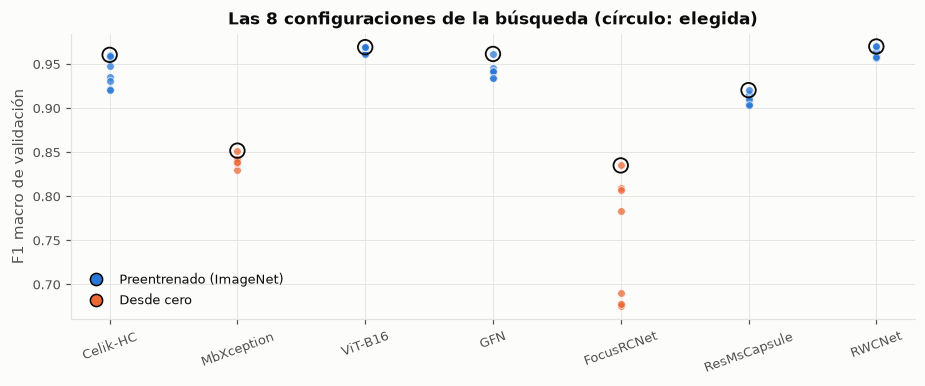

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for i, m in enumerate(E2_MODELS):
    v = hp[hp.model == m].val_f1_macro.to_numpy()
    ax.scatter(np.full(len(v), i), v, s=26, color=FG.color_regimen(m), alpha=0.75, edgecolor=FG.SURFACE, lw=0.6, zorder=3)
    ax.scatter(i, sel.loc[m, "val_f1_macro"], s=90, facecolor="none", edgecolor=FG.INK, lw=1.2, zorder=4)
ax.set_xticks(range(len(E2_MODELS)), E2_MODELS, rotation=20)
ax.set_ylabel("F1 macro de validación"); ax.set_title("Las 8 configuraciones de la búsqueda (círculo: elegida)")
FG.leyenda_regimen(ax, loc="lower left"); plt.tight_layout(); plt.show()

## 11.5 Desviaciones respecto a los artículos

Cada implementación registra sus desviaciones en `model_info.pkl`. Se deben a tres motivos: el protocolo común (entrada de 224×224, AdamW, *dropout* para el espacio de búsqueda), detalles que los artículos no declaran (variante de ViT, temperatura de destilación, núcleos de las cápsulas) y la corrección de la selección de época con el conjunto de prueba en Celik-HC.

In [5]:
tm = pd.read_csv(RES / "summary" / "tabla_modelos.csv").set_index("model").loc[E2_MODELS]
display(tm[["defines_architecture", "pretrained", "normalization", "loss", "deviations"]]
        .rename(columns={"defines_architecture": "arquitectura definida", "pretrained": "preentrenado",
                         "normalization": "normalización", "loss": "pérdida", "deviations": "desviaciones"}))

,arquitectura definida,preentrenado,normalización,pérdida,desviaciones
model,,,,,
Celik-HC,sí (código oficial),True,imagenet,ce,"PyTorch en lugar de Keras con pesos ImageNet de torchvision, Dropout antes de la prime..."
MbXception,sí (código oficial),False,train,ce,"Entrada 224x224 en lugar de 229x229, AdamW en lugar de SGD con momento, Dropout antes ..."
ViT-B16,"parcial (ViT estándar; variante no declarada, se asume B/16)",True,imagenet,ce,"Variante ViT-B/16 asumida, Lote 32 en lugar de 512"
GFN,sí (dimensiones de cada etapa en el texto),True,imagenet,ce,Proyección 2048x7x7 -> 1000x4x4 mediante conv 1x1 y pooling adaptativo (el texto no la...
FocusRCNet,sí (Tabla 1),False,imagenet,kd,"Entrada 224x224 en lugar de 380x380, T = 4.0 y alpha = 0.7 (no declarados), Factor de ..."
ResMsCapsule,parcial (estructura y dimensiones de cápsulas),True,imagenet,margin,"ResNet-18 hasta layer3 con pesos ImageNet, 32 tipos de cápsula por rama y núcleos 5/3/..."
RWCNet,sí (puntos de fusión y pérdida auxiliar),True,imagenet,aux,Rama auxiliar con pooling adaptativo a 5x5 para unificar resoluciones


## 11.6 Entorno, determinismo y registro

Las corridas se repartieron entre dos máquinas, con el mismo código, la misma caché de datos y las mismas semillas:

| Componente | Hardware | Software |
|---|---|---|
| ViT-B16, GFN, Celik-HC; réplica del paper guía | Colab Pro, NVIDIA A100-SXM4 (80 GB y 40 GB) | Python 3.13.16, PyTorch 2.14.1+cu130, CUDA 13.0 |
| MbXception, FocusRCNet (y su profesor), ResMsCapsule, RWCNet; ablaciones | Portátil, NVIDIA RTX 4060 Laptop (8 GB), Ryzen 7 8845HS, 31 GB de RAM, Windows 11 | Python 3.12.10, PyTorch 2.14.1+cu130, CUDA 13.0 |
| CNN, MobileNetV2, ResNet-18 (capítulo 4) | Mismo portátil | Entorno del capítulo 4 (`requirements-lock.txt`) |

**Determinismo.** Cada corrida fija las semillas de Python, NumPy y PyTorch. Activa `cudnn.deterministic`, desactiva `cudnn.benchmark` y activa `torch.use_deterministic_algorithms` en modo de advertencia con `CUBLAS_WORKSPACE_CONFIG=:4096:8`. El orden de los lotes y el aumento dependen solo de la semilla y de la época. Como evidencia, el reentrenamiento de las 8 semillas de ViT-B16 en otra sesión de Colab (sección 15.2) reprodujo la misma mejor época, el mismo F1 y el 100 % de las predicciones de prueba. Entre máquinas distintas (A100 y RTX 4060) no esperamos identidad bit a bit.

**Registro de experimentos.** No usamos MLflow ni Weights & Biases. Cada corrida guarda en su carpeta:

- la configuración (`config.json`, con la versión del código);
- el entorno (`env.pkl`);
- la historia por época;
- las predicciones de validación y prueba;
- las métricas, los tiempos, la información del modelo y un archivo `DONE` al terminar.

Los registros de ejecución con marca de tiempo están en `entregable2/results/logs/`. Las versiones exactas de las dependencias están en `entregable2/results/common/requirements-lock.txt`.

In [6]:
env = pd.DataFrame([{**{k: v for k, v in load_pickle(run_dir(m, 0) / "env.pkl").items() if k in
                         ("gpu", "python", "torch", "cuda", "driver", "platform")},
                     "modelo": m, "versión del código": json.load(open(run_dir(m, 0) / "config.json")).get("code_version")}
                    for m in E2_MODELS])
display(env.set_index("modelo"))
vit = pd.DataFrame([json.load(open(run_dir("ViT-B16", s) / "gradcam_origen.json")) for s in SEEDS])
display(vit[["semilla", "mejor_epoca_original", "mejor_epoca_reentrenado", "concordancia_predicciones_prueba",
             "f1_macro_prueba_original", "f1_macro_prueba_reentrenado"]])

,python,torch,cuda,gpu,driver,platform,versión del código
modelo,,,,,,,
Celik-HC,3.13.16,2.14.1+cu130,13.0,NVIDIA A100-SXM4-80GB,580.82.07,colab,77354957acdb
MbXception,3.12.10,2.14.1+cu130,13.0,NVIDIA GeForce RTX 4060 Laptop GPU,592.82,local,77354957acdb
ViT-B16,3.13.16,2.14.1+cu130,13.0,NVIDIA A100-SXM4-80GB,580.82.07,colab,77354957acdb
GFN,3.13.16,2.14.1+cu130,13.0,NVIDIA A100-SXM4-80GB,580.82.07,colab,77354957acdb
FocusRCNet,3.12.10,2.14.1+cu130,13.0,NVIDIA GeForce RTX 4060 Laptop GPU,592.82,local,77354957acdb
ResMsCapsule,3.12.10,2.14.1+cu130,13.0,NVIDIA GeForce RTX 4060 Laptop GPU,592.82,local,77354957acdb
RWCNet,3.12.10,2.14.1+cu130,13.0,NVIDIA GeForce RTX 4060 Laptop GPU,592.82,local,77354957acdb


,semilla,mejor_epoca_original,mejor_epoca_reentrenado,concordancia_predicciones_prueba,f1_macro_prueba_original,f1_macro_prueba_reentrenado
0,0,43,43,1.0,0.938753,0.938753
1,1,12,12,1.0,0.919271,0.919271
2,2,33,33,1.0,0.932752,0.932752
3,3,11,11,1.0,0.946453,0.946453
4,4,24,24,1.0,0.928985,0.928985
5,5,15,15,1.0,0.941116,0.941116
6,6,43,43,1.0,0.964849,0.964849
7,7,8,8,1.0,0.930085,0.930085


## 11.7 Fichas de modelo (plantilla de la sección 11.3)

In [7]:
rows = []
for m in E2_MODELS:
    info = load_pickle(run_dir(m, 0) / "model_info.pkl")
    tim = [load_pickle(run_dir(m, s) / "timing.pkl") for s in SEEDS]
    hist = [load_pickle(run_dir(m, s) / "history.pkl") for s in SEEDS]
    cfg = json.load(open(run_dir(m, 0) / "config.json"))
    rows.append({
        "modelo": m, "DOI": info.get("doi"), "preentrenamiento": "ImageNet-1k (torchvision)" if info.get("pretrained") else "ninguno",
        "parámetros (M)": info["params_total"] / 1e6, "GFLOPs por imagen": info.get("gflops"),
        "configuración (lr / wd / dropout)": f"{sel.loc[m, 'lr']:.1e} / {sel.loc[m, 'weight_decay']:.0e} / {sel.loc[m, 'dropout']}",
        "épocas efectivas (media)": np.mean([t["epochs_run"] for t in tim]),
        "mejor época (media)": np.mean([t["best_epoch"] for t in tim]),
        "minutos por corrida": np.mean([t["train_time_s"] for t in tim]) / 60,
        "latencia ms/imagen (lote)": np.mean([t["inference"]["ms_per_image_mean"] for t in tim]),
        "latencia lote 1 (ms)": np.mean([t["inference"]["latency_bs1_ms_mean"] for t in tim]),
        "memoria pico (MB)": np.mean([max(h["gpu_mem_max_MB"]) for h in hist]),
        "GPU": load_pickle(run_dir(m, 0) / "env.pkl")["gpu"].replace("NVIDIA ", ""),
    })
fichas = pd.DataFrame(rows).set_index("modelo")
display(fichas.round(2).T)

modelo,Celik-HC,MbXception,ViT-B16,GFN,FocusRCNet,ResMsCapsule,RWCNet
DOI,10.1007/s00371-025-04031-3,10.1109/ACCESS.2020.3016116,10.3390/su132111572,10.3390/electronics14010075,10.1186/s42492-023-00146-3,10.1007/s11356-023-27970-7,10.1109/ACCESS.2024.3354774
preentrenamiento,ImageNet-1k (torchvision),ninguno,ImageNet-1k (torchvision),ImageNet-1k (torchvision),ninguno,ImageNet-1k (torchvision),ImageNet-1k (torchvision)
parámetros (M),28.42,28.39,85.8,113.67,0.52,4.22,25.6
GFLOPs por imagen,6.45,12.39,35.13,11.35,0.25,2.84,9.18
configuración (lr / wd / dropout),3.0e-04 / 5e-04 / 0.2,3.0e-04 / 5e-04 / 0.4,3.0e-05 / 1e-04 / 0.4,1.0e-04 / 5e-04 / 0.2,1.0e-03 / 5e-04 / 0.4,3.0e-04 / 5e-04 / 0.2,9.0e-05 / 5e-04 / 0.2
épocas efectivas (media),42.0,57.62,36.62,40.75,60.0,44.5,33.0
mejor época (media),30.25,50.62,23.62,29.25,51.38,31.62,20.0
minutos por corrida,6.15,10.17,3.47,5.01,9.22,5.33,12.34
latencia ms/imagen (lote),1.12,1.42,0.46,0.97,0.37,0.4,2.28
latencia lote 1 (ms),34.97,10.83,11.93,29.59,9.45,5.6,56.49


**Incidencias.** Ninguna corrida divergió ni se descartó.

- **ViT-B16:** el Grad-CAM de la corrida original salió en ceros, porque la capa elegida no recibe gradiente en los tokens de los parches. Se cambió la capa y se reentrenaron las 8 semillas con la misma configuración para regenerarlo, con predicciones idénticas (tabla de la sección 11.6).
- **Colab:** se quedó sin unidades de cómputo antes de la ablación, que se ejecutó en el portátil con la misma versión del código.
- **Tiempos y latencias:** dependen de la GPU y solo se comparan entre modelos de la misma máquina.